# Final Project

___

Our overall metric of environmental health makes a neighborhood the best because it is a measure of an absolutely non-negotiable baseline of human living quality rather than something superficial or temporary. Environmental health directly connects with daily physical health and mental wellbeing. Additionally, environmental health is equitable for the most part, ignoring income, age, or status. Both the infrastructure and the clean environment metrics are required to safely enjoy the green spaces.


**Air Quality**

___

A top neighborhood should have clean air in order to acheive this, there should be as many greenery as possible. I used the City of Pittsburgh Trees  dataset and it indicates data such as the size and the benefit of the tree. The more and bigger the tree is within a neighborhood, the better the air quality which make it a better neighborhood.

/scratch/slurm-45222/ipykernel_1721236/3340728091.py:6: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  airQuality = pd.read_csv("https://data.wprdc.org/datastore/dump/1515a93c-73e3-4425-9b35-1cd11b2196da",


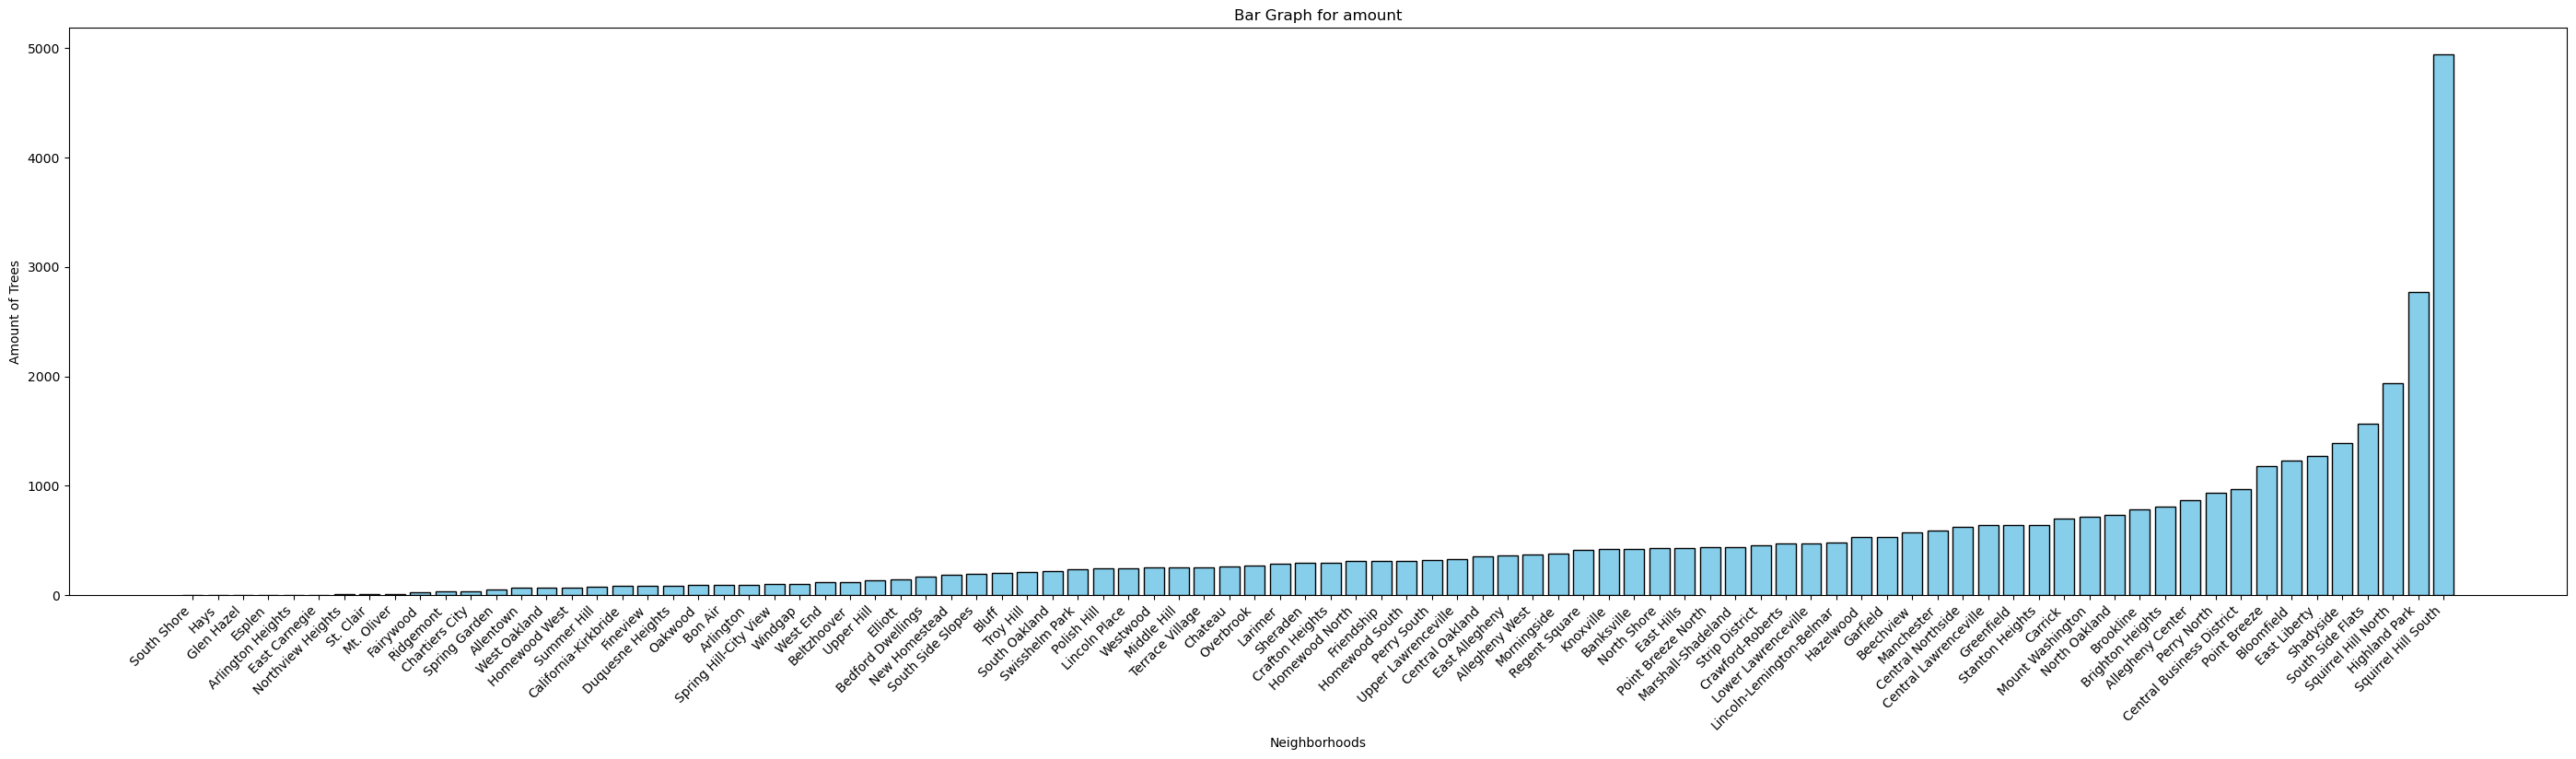

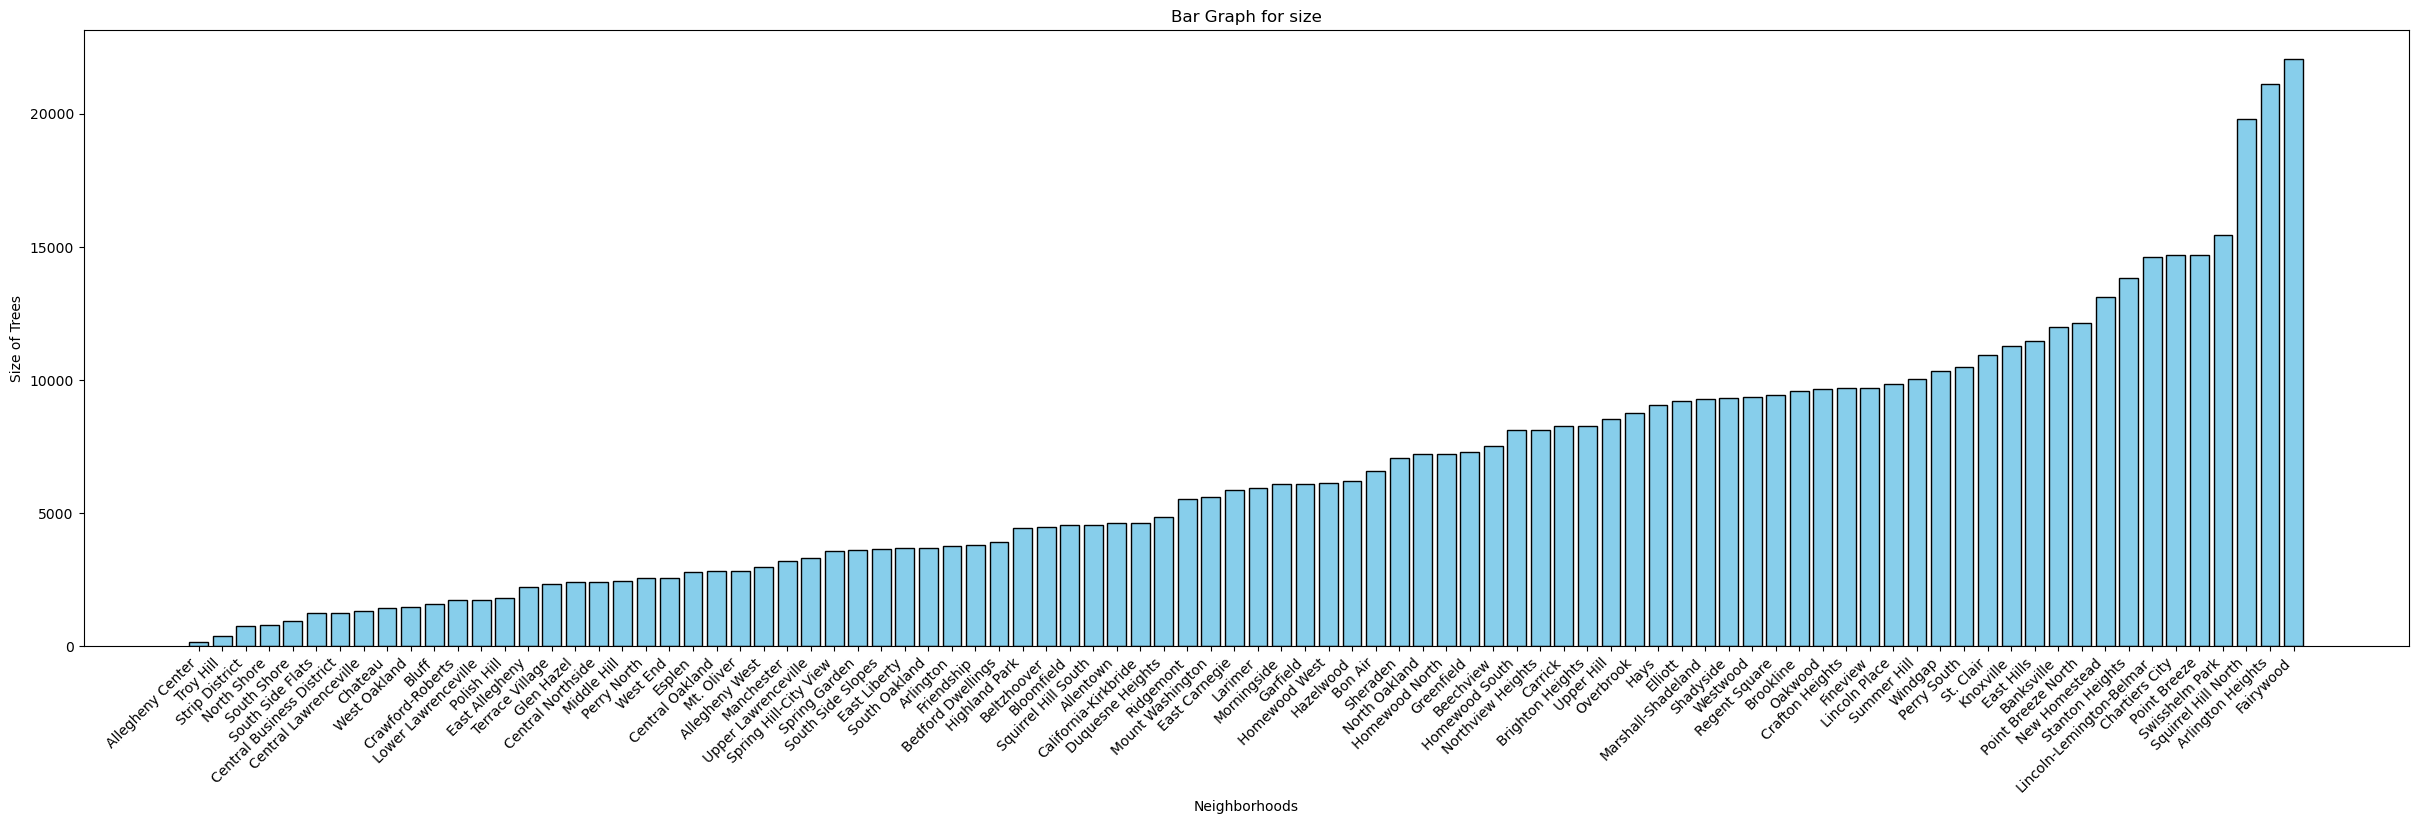

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#import dataset
airQuality = pd.read_csv("https://data.wprdc.org/datastore/dump/1515a93c-73e3-4425-9b35-1cd11b2196da", 
                           parse_dates=True)

air_dict = {}

for index, row in airQuality.iterrows():
    neighborhood = row['neighborhood']
    height = row['height']
    diameter = row['diameter_base_height']
    volume = np.pi * (diameter / 2)**2 * height
    
    if pd.isna(neighborhood):
        continue
    if pd.isna(height) or pd.isna(diameter):
        continue
    if neighborhood not in air_dict:
        air_dict[neighborhood] = {'volume': volume, 'amount': 1}
    else:
        air_dict[neighborhood]['volume'] += volume
        air_dict[neighborhood]['amount'] += 1
    
neighborhoods = []
volume = []
amount = []

for neighborhood, data in air_dict.items():
    neighborhoods.append(neighborhood)
    volume.append(data['volume'] / data['amount'])
    amount.append(data['amount'])

sort1 = np.argsort(amount)
neighborhoods1 = np.array(neighborhoods)[sort1]
amount = np.array(amount)[sort1]

sort2 = np.argsort(volume)
neighborhoods2 = np.array(neighborhoods)[sort2]
volume = np.array(volume)[sort2]

plt.figure(figsize=(35, 8))
plt.bar(neighborhoods1, amount, color='skyblue', edgecolor='black')
plt.title('Bar Graph for amount')
plt.xlabel('Neighborhoods')
plt.ylabel('Amount of Trees')
plt.xticks(rotation=45, ha='right')

plt.figure(figsize=(30, 8))
plt.bar(neighborhoods2, volume, color='skyblue', edgecolor='black')
plt.title('Bar Graph for size')
plt.xlabel('Neighborhoods')
plt.ylabel('Size of Trees')
plt.xticks(rotation=45, ha='right')

plt.show()
